# PROJECT DESCRIPTION

*In this Data Tale, a handwritten digits recognition system will be implemented with the famous
MNIST data set. This is not a new topic and the after several decades, the MNIST data set is still
very popular and important for evaluation and validation of new algorithms.*

*Handwritten digits recognition problem has been studied by researchers since 1999 with almost
all the algorithms designed by then and even until now. The test error rate decreased from 12% in
1999 by linear classifier to 0.23% in 2012 by convolutional neural nets.*

*Our goal is to correctly identify digits from a dataset of tens of thousands of handwritten
images.*

# STATE OF ART

*MNIST (&quot;Modified National Institute of Standards and Technology&quot;) is the de facto “hello world”
dataset of computer vision. Since its release in 1999, this classic dataset of handwritten images
has served as the basis for benchmarking classification algorithms. As new machine learning
techniques emerge, MNIST remains a reliable resource for researchers and learners alike.*

*A popular demonstration of the capability of deep learning techniques is object recognition in
image data. The hello world of object recognition for machine learning and deep learning is
the MNIST dataset for handwritten digit recognition. In this project we will discover how
to develop a deep learning model to achieve near state-of-the-art performance on the MNIST
handwritten digit recognition task in Python using the Keras deep learning library*

----

**Acknowledgements** 

*More details about the dataset, including algorithms that have been tried on it and their levels of success, can be found at [http://yann.lecun.com/exdb/mnist/index.html].*

*The dataset is made available under a Creative Commons Attribution-Share Alike 3.0 license.*

# UNDERSTANDING OF DATA

## Data Description

- MNIST - Mixed National Institute of Standards and Technology database.
- Created by - Yaan LeCun, Corinna Cortes, Christopher Burges.
- Image size - 28 x 28 pixel square (784 pixels in total).
- This pixel-value is an integer between 0 and 255, inclusive.
- Each pixel column in the training set has a name like pixelx, where x is an integer between 0 and 783, inclusive.
- Training images - 42000
- Testing Images - 28000

## Organizing imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
pd.set_option('display.max_columns', 100) # Show upto 100 columns when exploring the data
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook
%matplotlib inline
from zipfile import ZipFile
from keras.datasets import mnist
from keras.utils import np_utils
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

Using TensorFlow backend.


## Getting Data

*You can get the data from [kaggle](https://www.kaggle.com/c/digit-recognizer)*

*The Downloded file from kaggle is a zip file and to unzip that we need to use ZipFile module or you could have command line to unzip.*

In [2]:
# Extract all the contents of zip file in the current directory
with ZipFile('digit-recognizer.zip', 'r') as zipObj:
   zipObj.extractall()

*Now that we have extracted the train test files from zip file, we are ready to import them.*

In [3]:
# Importing train
df = pd.read_csv("train.csv")
train = df.as_matrix()
# Importing test
test= pd.read_csv("test.csv")

In [4]:
train_y = train[:,0]
train_x = train[:,1:]

In [5]:
print("Training Set : ", train_x.shape)
print("Training labels : ", train_y.shape)
print("Testing Set : ", test.shape)

Training Set :  (42000, 784)
Training labels :  (42000,)
Testing Set :  (28000, 784)


*So we have 42000 training samples which are labeled and 28000 testing data with out labels which we need to predict.*

*This is lot of work to get the dataset, There is a much easier way to get the data set. Thanks! to Keras Team and we will also get all the 70000 data points labeled.*

*Lets see how writing one line of code can get and will also split the data for us in to testing and training set*

In [6]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

*You can also download MNIST Data from SKlearm Dataset by using this following code.*

**from sklearn.datasets import fetch_mldata**

**mnist = fetch_mldata('MNIST original', data_home=custom_data_home)**

**mnist.data.shape**

(70000, 784)

**mnist.target.shape**

(70000,)

*What you can see here is you get all the 70000 data points and its labels all annotated. And then using Sklearn's train-test Split you can split it according to your need.*

In [7]:
print("Shape Training Set : ", X_train.shape)
print("Shape Training labels : ", y_train.shape)
print("Testing Set : ", X_test.shape)
print("Shape Testing labels : ", y_test.shape)

Shape Training Set :  (60000, 28, 28)
Shape Training labels :  (60000,)
Testing Set :  (10000, 28, 28)
Shape Testing labels :  (10000,)


*Lets look at the images from these pixel values*

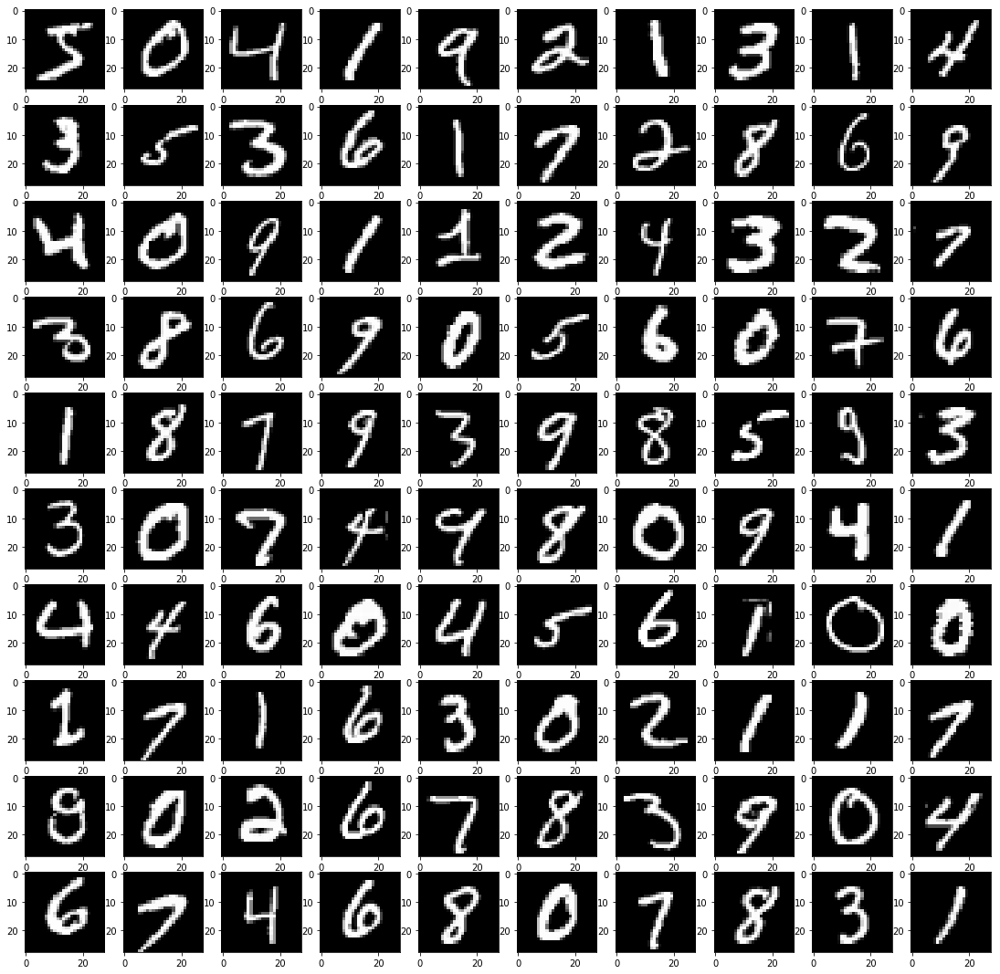

In [8]:
# plot 100 images as gray scale
plt.figure(figsize=(19,19))
for i in range(0,100):
    plt.subplot(10,10,i+1)
    plt.imshow(X_train[i], cmap=plt.get_cmap( 'gray' ))
# show the plot
plt.show()

# DATA PREPROCESSING

*The training dataset is structured as a 3-dimensional array of instance, image width and image height. In this case the 28 28 sized images will be 784 pixel input vectors. We can do this transform easily using the reshape() function on the NumPy array. The pixel values are integers, so we cast them to floating point values so that we can normalize them easily in the
next step.*

In [9]:
# flatten 28*28 images to a 784 vector for each image
num_pixels = X_train.shape[1] * X_train.shape[2]
X_train = X_train.reshape(X_train.shape[0], num_pixels).astype( 'float32' )
X_test = X_test.reshape(X_test.shape[0], num_pixels).astype( 'float32' )

*After flattening the pixels, Lets check the shape of the Dataset*

In [10]:
print("Shape Training Set : ", X_train.shape)
print("Shape Training labels : ", y_train.shape)
print("Testing Set : ", X_test.shape)
print("Shape Testing labels : ", y_test.shape)

Shape Training Set :  (60000, 784)
Shape Training labels :  (60000,)
Testing Set :  (10000, 784)
Shape Testing labels :  (10000,)


*The pixel values are gray scale between 0 and 255. It is almost always a good idea to perform some scaling of input values when using neural network models. Because the scale is well known and well behaved, we can very quickly standardize the pixel values to the range 0 and 1 by dividing each value by the maximum of 255.*

In [11]:
# normalize inputs from 0-255 to 0-1
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255

*Finally, the output variable is an integer from 0 to 9. This is a multiclass classification problem. As such, it is good practice to use a one hot encoding of the class values, transforming the vector of class integers into a binary matrix. We can easily do this using the built-in np utils.to categorical() helper function in Keras.*

In [12]:
np_utils.to_categorical(y_train)

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], dtype=float32)

In [13]:
np_utils.to_categorical(y_train).shape

(60000, 10)

In [14]:
# one hot encode outputs
y_train_enc = np_utils.to_categorical(y_train)
y_test_enc = np_utils.to_categorical(y_test)
num_classes = y_test_enc.shape[1]

# Data Cleaning

*Lets check if there are NA null values in our dataset*

In [15]:
np.isnan(X_train).any(), np.isnan(X_test).any()

(False, False)

In [16]:
np.isnan(y_train).any(), np.isnan(y_test).any()

(False, False)

*We can see that there are no NA Values in the Dataset. So we should get going.*

# Exploratory Data Analysis(EDA)

*Balance of digits in labeled target variable*

In [45]:
count_df= pd.DataFrame({'Digits': y_train.astype('int64')})
count_df=pd.DataFrame({"Digit":count_df.Digits.value_counts().index, "Counts": count_df.Digits.value_counts().values})
count_df['Percentage']= count_df.Counts.apply(lambda x: f"{((x/60000)*100):.2f} %")

In [46]:
count_df

,Digit,Counts,Percentage
0,1,6742,11.24 %
1,7,6265,10.44 %
2,3,6131,10.22 %
3,2,5958,9.93 %
4,9,5949,9.92 %
5,0,5923,9.87 %
6,6,5918,9.86 %
7,8,5851,9.75 %
8,4,5842,9.74 %
9,5,5421,9.04 %


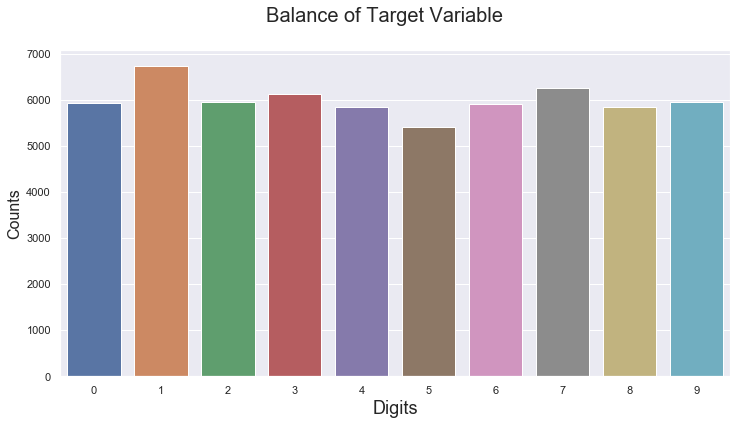

In [51]:
fig = plt.figure(figsize=(12,6))
sns.set(style="darkgrid")
sns.countplot(x=y_train.tolist());
fig.suptitle('Balance of Target Variable', fontsize=20)
plt.xlabel('Digits', fontsize=18)
plt.ylabel('Counts', fontsize=16)
plt.show();

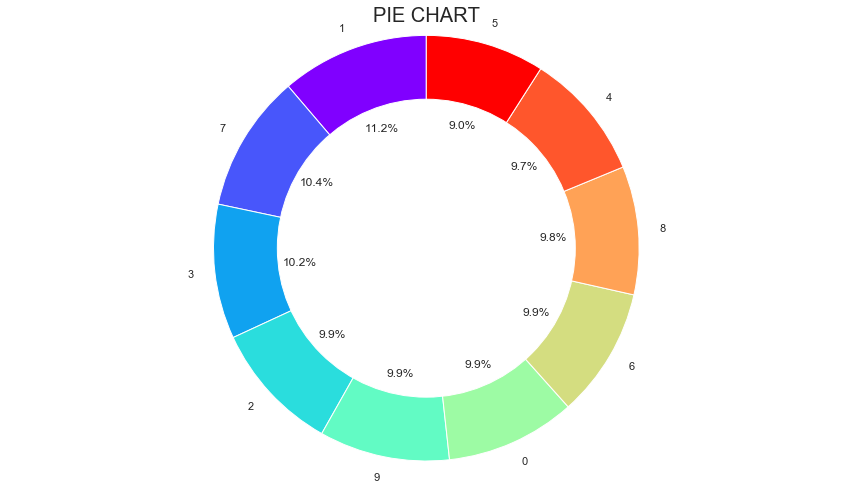

In [56]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt

colors = cm.rainbow(np.linspace(0, 1, 10))
 
fig1, ax1 = plt.subplots()
ax1.pie(count_df.Counts, colors = colors, labels=count_df.Digit, autopct='%1.1f%%', startangle=90)
#draw circle
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# Equal aspect ratio ensures that pie is drawn as a circle
ax1.axis('equal') 
plt.suptitle("PIE CHART", fontsize=20)
plt.tight_layout()
plt.show()

*Enough of these boring static plots Lets bring in some interactivity to our plots*

In [18]:
import plotly.offline as pyo
import plotly.graph_objs as go
from plotly import tools
pyo.init_notebook_mode(connected=True) 
unique, counts = np.unique(y_train.tolist(), return_counts=True)

trace1 = go.Bar(
            x=unique,
            y=counts,
            text=counts,
            textposition = 'auto',
            marker=dict(
                color='#7245AC',
                line=dict(
                    color='rgb(8,48,107)',
                    width=1.5)
            ),
            opacity=0.8
            
    )

trace2 = go.Pie(labels=unique.tolist(), 
                values=counts.tolist()
               )               

layout = go.Layout(title ='VALUE COUNTS OF TARGET VARIABLE',
                    font= dict(family= 'Times New Roman', size= 12))


fig = go.Figure(data=[trace1],layout=layout)
pyo.iplot(fig, filename='Bie Plot')

pyo.iplot([trace2], filename='Pie Chart')

In [19]:
#Mean Intensity by Row
mean_intensity= X_train.mean(axis=1)

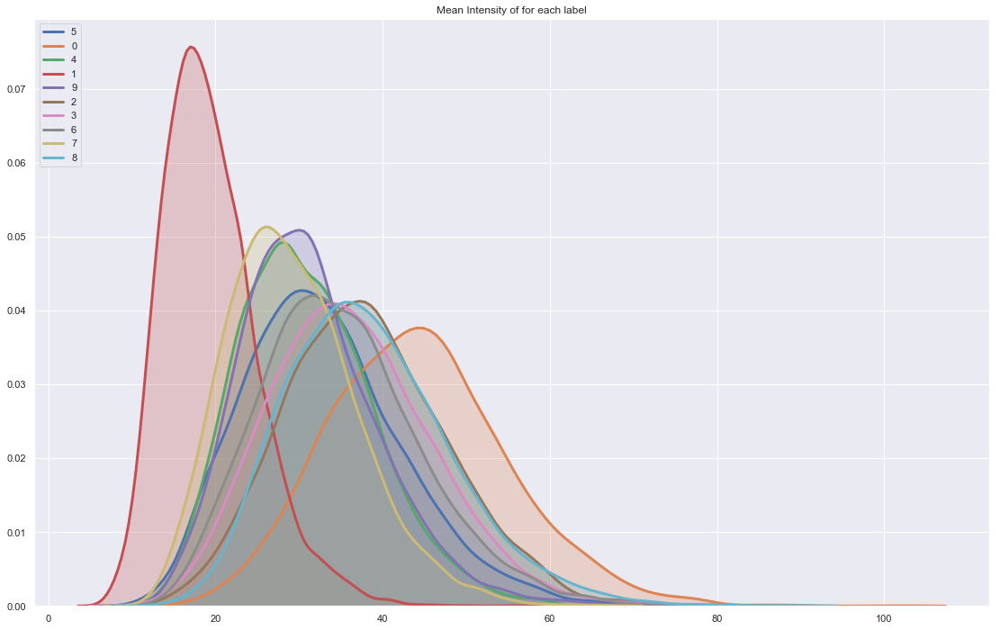

In [20]:
df= pd.DataFrame({'intensity': mean_intensity, 'label': y_train})
groups  = df.label.unique().tolist()
ins=list()
for group in groups:
    ins.append(df.loc[df.label== group]['intensity'].tolist())
    
fig = plt.figure(figsize=(19,12))
ax = fig.add_subplot(1, 1, 1)

for inte, group in zip(ins, groups):
    sns.distplot(inte, hist = False, kde = True, kde_kws = {'shade': True, 'linewidth': 3}, label=group)

plt.title('Mean Intensity of for each label')
plt.legend(loc=2)
plt.show()

*What can we observe from the histograms above? Well most intensity distributions seem roughly normally distributed but some have higher variance than others.*

*Lets Build of interactive distplot*

In [125]:
import plotly.offline as pyo
import plotly.figure_factory as ff

fig = ff.create_distplot(ins, groups)
pyo.iplot(fig, filename='IntensityPlot.html')

*Lets try to dig in more, and plot histogram for each digit*

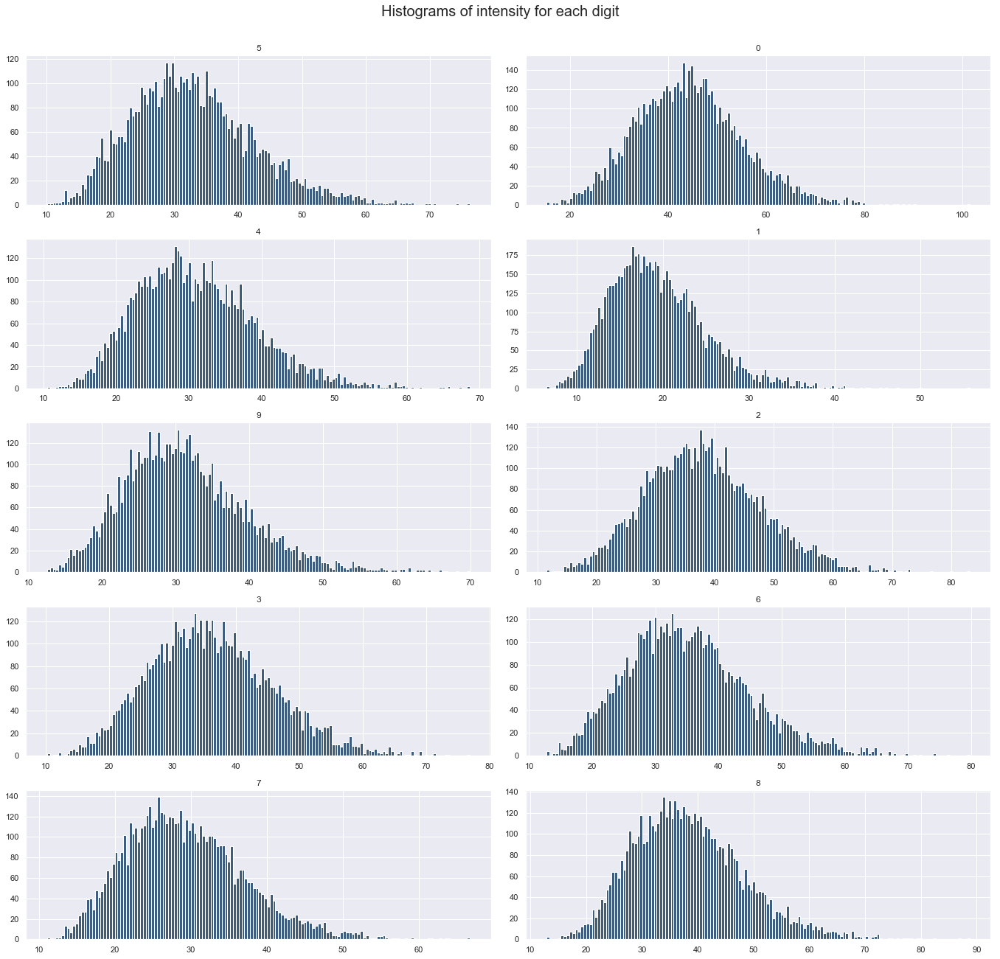

In [119]:
sns.set()
fig = plt.figure(figsize=(19, 19))
plt.suptitle('Histograms of intensity for each digit', fontsize=20)
for i in range(10):
    plt.subplot(5, 2, i + 1)
    f = plt.gca()
    f.set_title(groups[i])
    plt.hist( ins[i], bins=150, color='#3F5D7D')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])

Distributions for 4, 7 and 9 are less “normal” than the distrubution for others. The diestribution for 9 looks almost bimodal - a telling sign thay perhaps there are two different ways people tend to write their 4's, 7's and 9's. Let’s take a look at some images of fours, sevens and Nines.

In [107]:
# Creating the Dataframe out of numpy array
df=pd.DataFrame()
for i in range(X_train.shape[1]):
    df[f'Intensity {i}']= X_train[:, i]
df['label']= y_train.astype('int64')
# Data frame for only 4
df_4= df.loc[df.label == 4]
#Creating a numpy array out of it
array_4= np.array(df_4.iloc[:, :-1], dtype="float64")

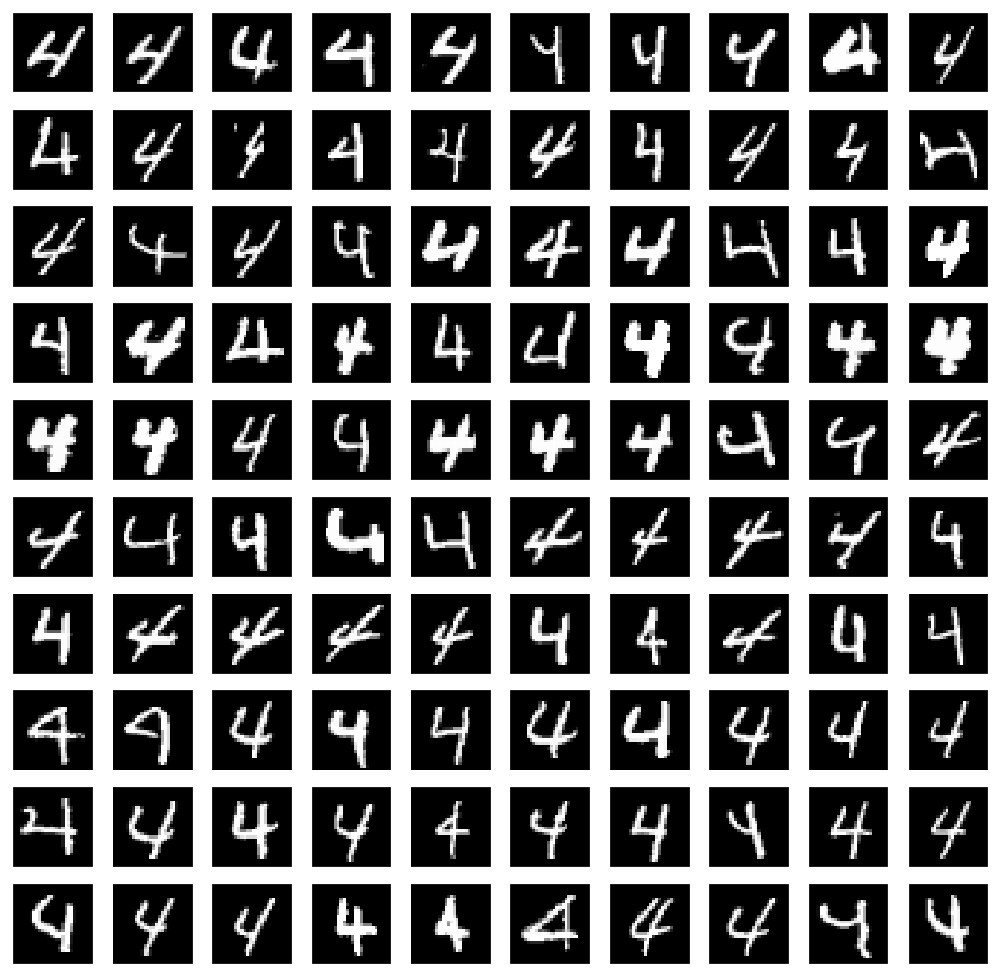

In [112]:
# plot 100 images of digit 4 as gray scale
plt.figure(figsize=(19,19))
for i in range(100,200):
    plt.subplot(10,10,i-100+1)
    plt.imshow(array_4[i].reshape(28,28), cmap=plt.get_cmap( 'gray' ))
    plt.xticks(())
    plt.yticks(())
# show the plot
plt.show()

*Lets do the same for digit 7*

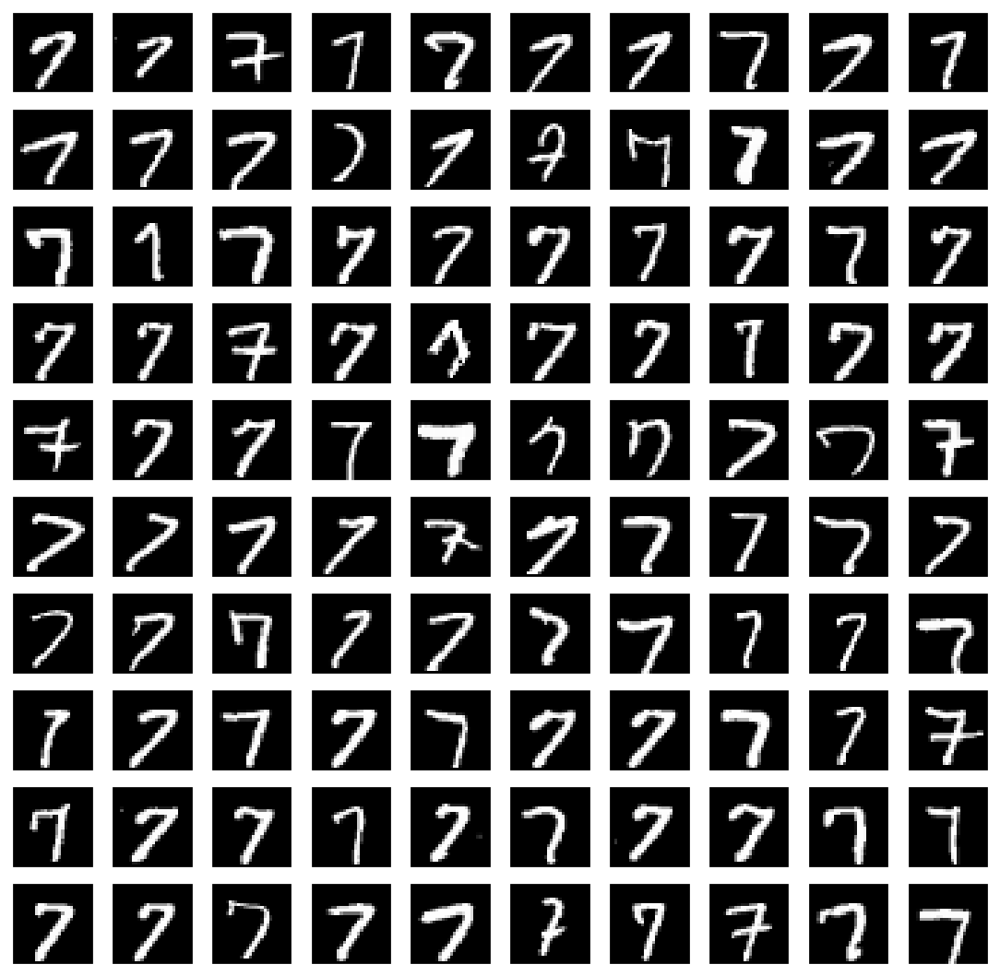

In [113]:
# Data frame for only 7
df_7= df.loc[df.label == 7]
#Creating a numpy array out of it
array_7= np.array(df_7.iloc[:, :-1], dtype="float64")

# plot 100 images of digit 7 as gray scale
plt.figure(figsize=(19,19))
for i in range(0,100):
    plt.subplot(10,10,i+1)
    plt.imshow(array_7[i].reshape(28,28), cmap=plt.get_cmap( 'gray' ))
    plt.xticks(())
    plt.yticks(())
# show the plot
plt.show()

*Lets do the same for 9*

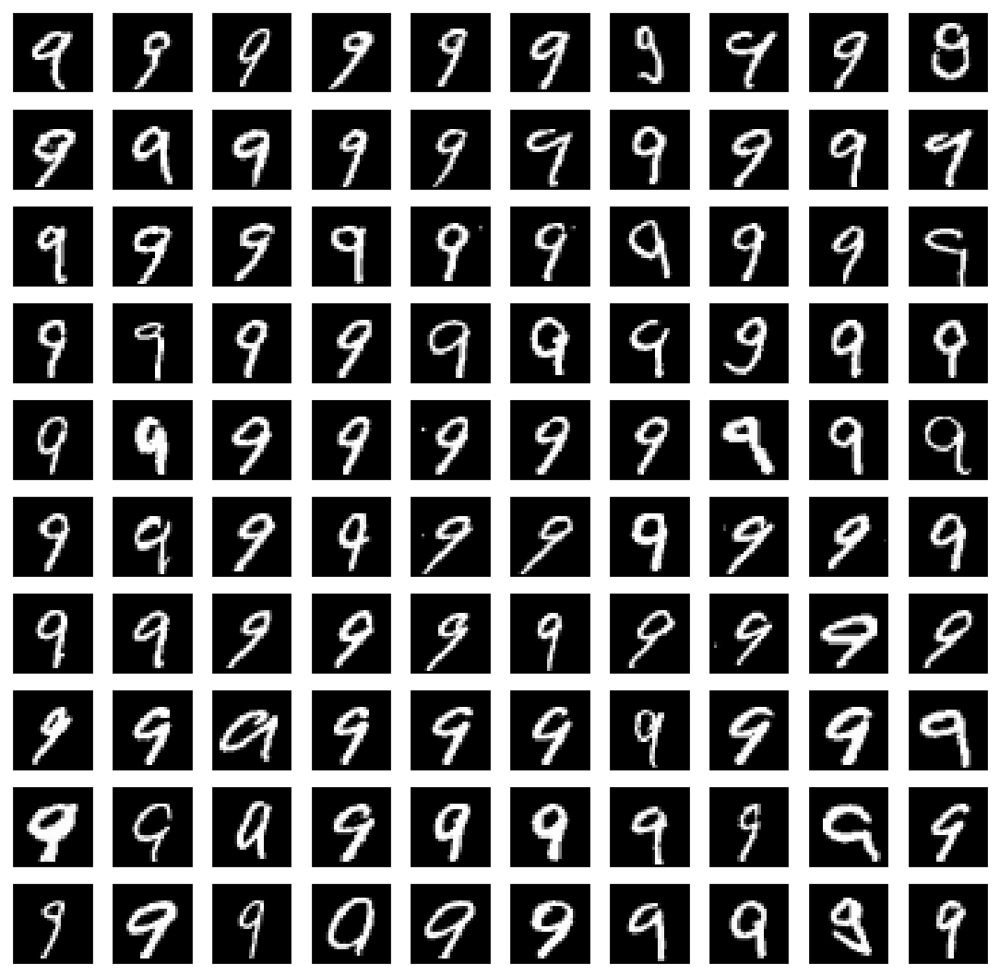

In [114]:
# Data frame for only 9
df_9= df.loc[df.label == 9]
#Creating a numpy array out of it
array_9= np.array(df_9.iloc[:, :-1], dtype="float64")

# plot 100 images of digit 9 as gray scale
plt.figure(figsize=(19,19))
for i in range(0,100):
    plt.subplot(10,10,i+1)
    plt.imshow(array_9[i].reshape(28,28), cmap=plt.get_cmap( 'gray' ))
    plt.xticks(())
    plt.yticks(())
# show the plot
plt.show()

*You can clearly see that people tend to write digits like 4,5 and 9 in difrent ways*
![4](https://i.ibb.co/9q4CnCz/4.png)

![7](https://i.ibb.co/bP4zrwj/7.png)

![9](https://i.ibb.co/Ph84hqq/9.png)


*Thats why the distribution looks different, that might be the case with even 1, try exploring*

### Next we are going to Visualize the Data using some Dimensionality reductions Techniques and Clustering Algorithms

*Before Diving in specific dimensionality reduction algorithms, let’s take a look at the two main approaches to reducing dimensionality:*
- Projection
- Manifold Learning

**Projection:** In most real-world problems, training instances are not spread out uniformly across all dimensions. Many features are almost constant, while others are highly correlated. As a result, all training instances actually lie within (or close to) a much lower-dimensional subspace of the high-dimensional space. Now if we project every training
instance perpendicularly onto this subspace, We reduced the dataset’s dimensionality.



**Manifold Learning:** Manifold learning for dimensionality reduction has recently gained much attention to assist image processing tasks such as segmentation, registration, tracking, recognition, and computational anatomy.The drawbacks of PCA in handling dimensionality reduction problems for non-linear weird and curved shaped surfaces necessitated development of more advanced algorithms like Manifold Learning.The goal of the manifold-learning algorithms is to recover the original domain structure, up to some scaling and rotation. The nonlinearity of these algorithms allows them to reveal the domain structure even when the manifold is not linearly embedded.

#### Principal component Analysis
In a nutshell, PCA is a linear transformation algorithm that seeks to project the original features of our data onto a smaller set of features ( or subspace ) while still retaining most of the information. 
To do this the algorithm tries to find the most appropriate directions/angles ( which are the principal components ) that maximise the variance in the new subspace. Why maximise the variance though?

To answer the question, more context has to be given about the PCA method. One has to understand that the principal components are orthogonal to each other ( think right angle ). As such when generating the covariance matrix ( measure of how related 2 variables are to each other ) in our new subspace, the off-diagonal values of the covariance matrix will be zero and only the diagonals ( or eigenvalues) will be non-zero. It is these diagonal values that represent the variances of the principal components that we are talking about or information about the variability of our features.

Therefore when PCA seeks to maximise this variance, the method is trying to find directions ( principal components ) that contain the largest spread/subset of data points or information ( variance ) relative to all the data points present.

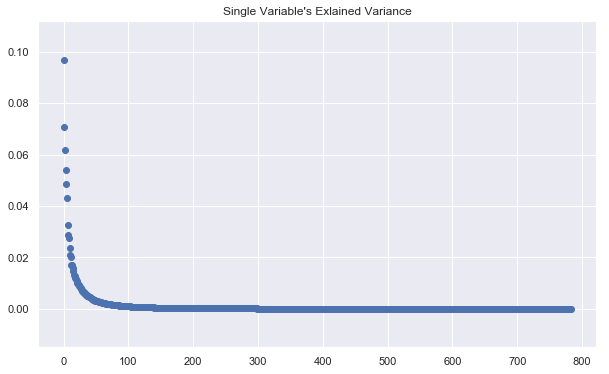

In [19]:
# Lets check the explained variance of each variables
from sklearn.decomposition import PCA

pca = PCA(n_components=784).fit(X_train_scaled)

plt.figure(figsize=(10,6))
plt.scatter(list(range(784)), pca.explained_variance_ratio_)
plt.title("Single Variable's Exlained Variance")
plt.show();

*You can clearly see that after a certain point the variance doesn't even change, It remains on the Zero Line. So, 70% of the variance can be explained by around 40- 50 features.*

**Choosing the number of components**

*A vital part of using PCA in practice is the ability to estimate how many components are needed to describe the data. This can be determined by looking at the cumulative explained variance ratio as a function of the number of components:*

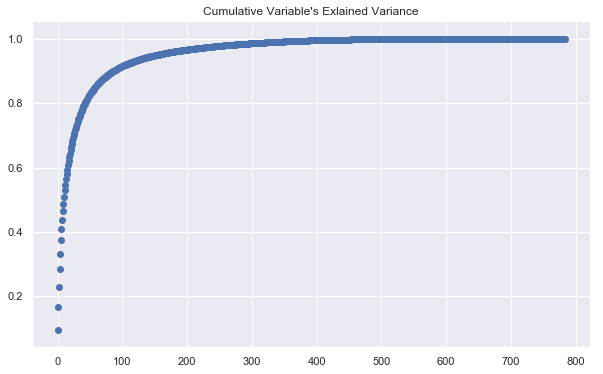

In [20]:
plt.figure(figsize=(10,6))
plt.scatter(list(range(784)), pca.explained_variance_ratio_.cumsum())
plt.title("Cumulative Variable's Exlained Variance")
plt.show();

*Based on this we can decide the number of variables according to the variance you want to reserve. Or simply using SKlearn PCA just feed in the variance to the n_components and you can get the Number of principal components you need to specify.*

In [21]:
pca = PCA(n_components=0.70).fit(X_train_scaled)
pca.n_components_

26

*We can see that about 70% of variance is explained by only 26 features out of the 784 features*

*Now Lets just get top 100 PCA components and plot them, Lets see what we will get*

In [22]:
pca = PCA(n_components=100).fit(X_train_scaled)
pca.explained_variance_ratio_

array([0.09704716, 0.07095955, 0.06169128, 0.05389448, 0.04868821,
       0.04312256, 0.03271949, 0.02883906, 0.02762043, 0.02357013,
       0.02109199, 0.02023   , 0.01715826, 0.01692121, 0.01578648,
       0.0148296 , 0.01324567, 0.01276904, 0.01187269, 0.0115269 ,
       0.01066172, 0.01006718, 0.00953579, 0.00912548, 0.00883409,
       0.00839323, 0.00812583, 0.00786371, 0.00744736, 0.00690863,
       0.00658097, 0.00648151, 0.00602618, 0.00586585, 0.00570024,
       0.00543631, 0.00505789, 0.00487861, 0.00481431, 0.00472269,
       0.00456749, 0.00444838, 0.00418504, 0.00398217, 0.00384976,
       0.00375105, 0.0036201 , 0.00351593, 0.00340058, 0.00321873,
       0.00319016, 0.00312806, 0.00295982, 0.00288953, 0.00284131,
       0.00271435, 0.0026952 , 0.00258463, 0.00253752, 0.00244767,
       0.00240502, 0.00239243, 0.00230401, 0.00221507, 0.00213704,
       0.00207192, 0.00202989, 0.00196719, 0.00192829, 0.00188577,
       0.00186676, 0.00181008, 0.00177454, 0.00174822, 0.00165

In [23]:
eigen_100 = pca.components_.reshape(100,28, 28)

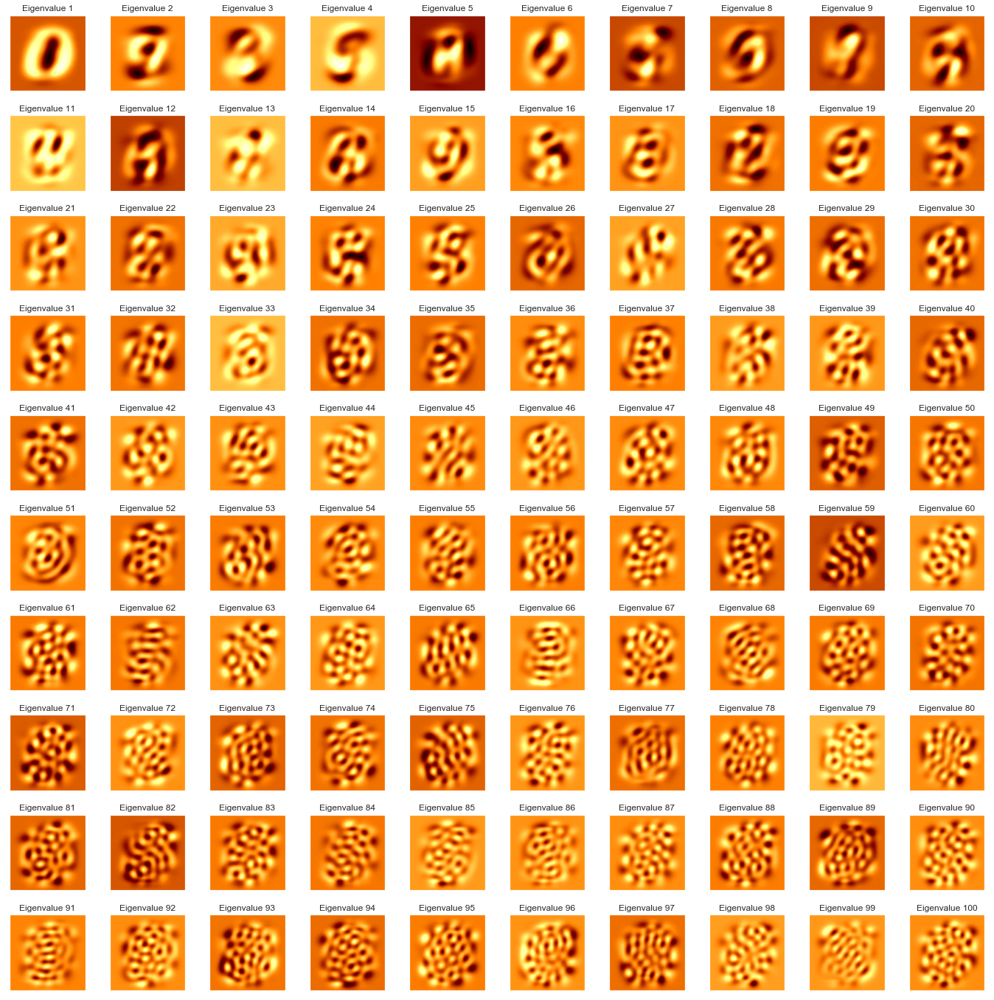

In [24]:
# lets Plot the first 100 eignenvalues
plt.figure(figsize=(19,19))
for i in list(range(100)):
    plt.subplot(10, 10, i + 1)
    plt.imshow(eigen_100[i], interpolation = "bicubic", cmap = "afmhot")
    title_text = 'Eigenvalue ' + str(i + 1)
    plt.title(title_text, size=12)
    plt.xticks(())
    plt.yticks(())

plt.tight_layout();

*This signal preserving/noise filtering property makes PCA a very useful feature selection routine—for example, rather than training a classifier on very high-dimensional data, you might instead train the classifier on the lower-dimensional representation, which will automatically serve to filter out random noise in the inputs.*

*Now lets visualize the data reducing the number of components to 2 using PCA*

In [25]:
# Call the PCA method with 2 components. 
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

In [26]:
X_train_scaled.shape, X_pca.shape

((60000, 784), (60000, 2))

In [27]:
pca_df= pd.DataFrame({'PC1': X_pca[:,0].astype('float64'), 'PC2': X_pca[:,1].astype('float64'), 
                     'label': y_train.astype('int64')})

In [28]:
pca_df.label= pca_df['label'].astype('category')

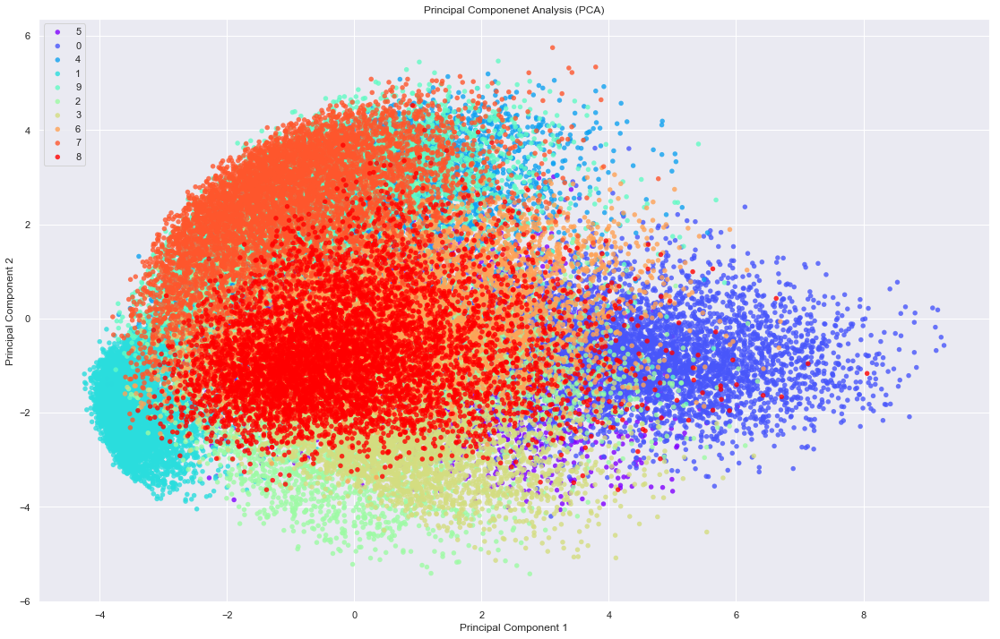

In [29]:
import matplotlib.cm as cm
groups  = pca_df.label.unique().tolist()
colors = cm.rainbow(np.linspace(0, 1, 10))
xs=list()
ys=list()
for group in groups:
    xs.append(pca_df.loc[pca_df.label== group]['PC1'].tolist())
    ys.append(pca_df.loc[pca_df.label== group]['PC2'].tolist())
    
fig = plt.figure(figsize=(19,12))
ax = fig.add_subplot(1, 1, 1)

for x,y, color, group in zip(xs, ys, colors, groups):
    ax.scatter(x, y, alpha=0.8, c=color, edgecolors='none', s=30, label=group)

plt.title('Principal Componenet Analysis (PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel("Principal Component 2")
plt.legend(loc=2)
plt.show()

*Lets bring some interactivity to the plot using Plotly*

In [30]:
# I have just ploted first 2000 data points beacuse rendering 60000 in Jupyter notebook will slow it down
pyo.init_notebook_mode(connected=True) 
data = [go.Scatter(
    x = X_pca[:2000,0],
    y = X_pca[:2000,1],
    mode = 'markers',
    showlegend = False,
    marker = dict(
        size = 8,
        color = y_train[:2000],
        colorscale ='Rainbow',
        showscale = False,
        line = dict(
            width = 2,
            color = 'rgb(255, 255, 255)'
        ),
        opacity = 0.8
    )
)]

layout = go.Layout(
    title= 'Principal Component Analysis (PCA)',
    hovermode= 'closest',
    height= 600,
    xaxis= dict(
         title= 'First Principal Component',
        ticklen= 8,
        zeroline= False,
        gridwidth= 2,
    ),
    yaxis=dict(
        title= 'Second Principal Component',
        ticklen= 8,
        gridwidth= 2,
    ),
    showlegend=True
)


fig = dict(data=data, layout=layout)
pyo.iplot(fig, filename='PCA_plot')

**Imagine just for a moment that we were not provided with the class labels to this digit set because after all PCA is an unsupervised method. Therefore how would we be able to separate out our data points in the new feature space? We can apply a clustering algorithm on our new PCA projection data and hopefully arrive at distinct clusters which would tell us something about the underlying class separation in the data.**


*Now Lets cluster these Principal Components using KMeans*

*K-Means is probably the most well know clustering algorithm. It’s taught in a lot of introductory data science and machine learning classes. It’s easy to understand and implement in code! Check out the graphic below for an illustration.*

![KMeans](https://cdn-images-1.medium.com/max/800/1*KrcZK0xYgTa4qFrVr0fO2w.gif)

*K-Means has the advantage that it’s pretty fast, as all we’re really doing is computing the distances between points and group centers; very few computations! It thus has a linear complexity O(n).*

*On the other hand, K-Means has a couple of disadvantages. Firstly, you have to select how many groups/classes there are. This isn’t always trivial and ideally with a clustering algorithm we’d want it to figure those out for us because the point of it is to gain some insight from the data. K-means also starts with a random choice of cluster centers and therefore it may yield different clustering results on different runs of the algorithm. Thus, the results may not be repeatable and lack consistency. Other cluster methods are more consistent.*

In [31]:
from sklearn.cluster import KMeans
# Set a KMeans clustering with 9 components cuz there are 9 class labels
kmeans = KMeans(n_clusters=10)
# Compute cluster centers and predict cluster indices
kmeans_10 = kmeans.fit_predict(X_pca)

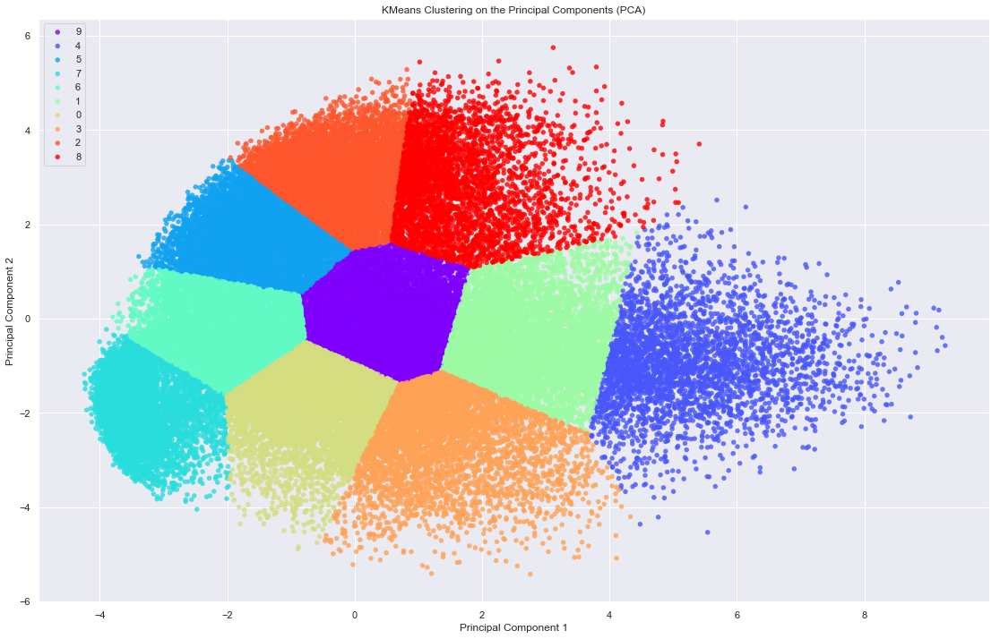

In [32]:
pca_df['kmeans']= kmeans_10
import matplotlib.cm as cm
groups  = pca_df.kmeans.unique().tolist()
colors = cm.rainbow(np.linspace(0, 1, 10))
xs=list()
ys=list()
for group in groups:
    xs.append(pca_df.loc[pca_df.kmeans== group]['PC1'].tolist())
    ys.append(pca_df.loc[pca_df.kmeans== group]['PC2'].tolist())
    
fig = plt.figure(figsize= (19, 12))
ax = fig.add_subplot(1, 1, 1)

for x,y, color, group in zip(xs, ys, colors, groups):
    ax.scatter(x, y, alpha=0.8, c=color, edgecolors='none', s=30, label=group)

plt.title('KMeans Clustering on the Principal Components (PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel("Principal Component 2")
plt.legend(loc=2)
plt.show();

*Visually, the clusters generated by the KMeans algorithm appear to provide a clearer demarcation amongst clusters as compared to naively adding in class labels into our PCA projections.*

*This should come as no surprise as PCA is meant to be an unsupervised method and therefore not optimised for separating different class labels.*

*Lets Plot the interactive plot for the same.*

In [33]:
# I have just ploted first 2000 data points beacuse rendering 60000 data points in Jupyter notebook will slow it down
data = [
    go.Scatter(
        x= X_pca[:2000, 0], 
        y= X_pca[:2000, 1], 
        mode="markers",
        showlegend=False,
        marker=dict(
            size=8,
            color = kmeans_10[:2000],
            colorscale = 'Rainbow',
            showscale=False, 
            line = dict(
                width = 2,
                color = 'rgb(255, 255, 255)'
            )))]

layout = go.Layout(
    title= 'KMeans Clustering',
    hovermode= 'closest',
    xaxis= dict(
         title= 'First Principal Component',
        ticklen= 8,
        zeroline= False,
        gridwidth= 2,
    ),
    yaxis=dict(
        title= 'Second Principal Component',
        ticklen= 8,
        gridwidth= 2,
    ),
    showlegend= True
)

fig = dict(data = data, layout = layout)
pyo.iplot(fig, filename= "KmeansPlot")

*Lets try another popular dimensionality reduction or supervised dimensionality Reduction Technique*

***Linear Discriminant Analysis*** *is a supervised algorithm as it takes the class label into consideration. It is a way to reduce ‘dimensionality’ while at the same time preserving as much of the class discrimination information as possible.*

*LDA helps you find the boundaries around clusters of classes. It projects your data points on a line so that your clusters are as separated as possible, with each cluster having a relative (close) distance to a centroid.*

*So the question arises- how are these clusters are defined and how do we get the reduced feature set in case of LDA?*

*Basically LDA finds a centroid of each class datapoints. For example with thirteen different features LDA will find the centroid of each of its class using the thirteen different feature dataset. Now on the basis of this, it determines a new dimension which is nothing but an axis which should satisfy two criteria:*
- *Maximize the distance between the centroid of each class.*
- *Minimize the variation (which LDA calls scatter and is represented by s2), within each category.*

Therefore the gist is:

(meana – meanb)/(Sa – Sb) = ideally large/ideally small

**Note:** Here ‘mean’ is nothing but the centroid of the class. Variation is nothing but the spread of data over the plane. So, if the variation of data is minimum, then less overlapping between the classes will be there and maximum separation will be maintained between the different classes.

*After a brief description on LDA, lets implement it using SKlearn*

In [34]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
lda = LDA(n_components=2)
X_lda = lda.fit_transform(X_train_scaled, y_train)

In [35]:
lda_df= pd.DataFrame({'LD1': X_lda[:, 0], 'LD2': X_lda[:, 1],'target': y_train})

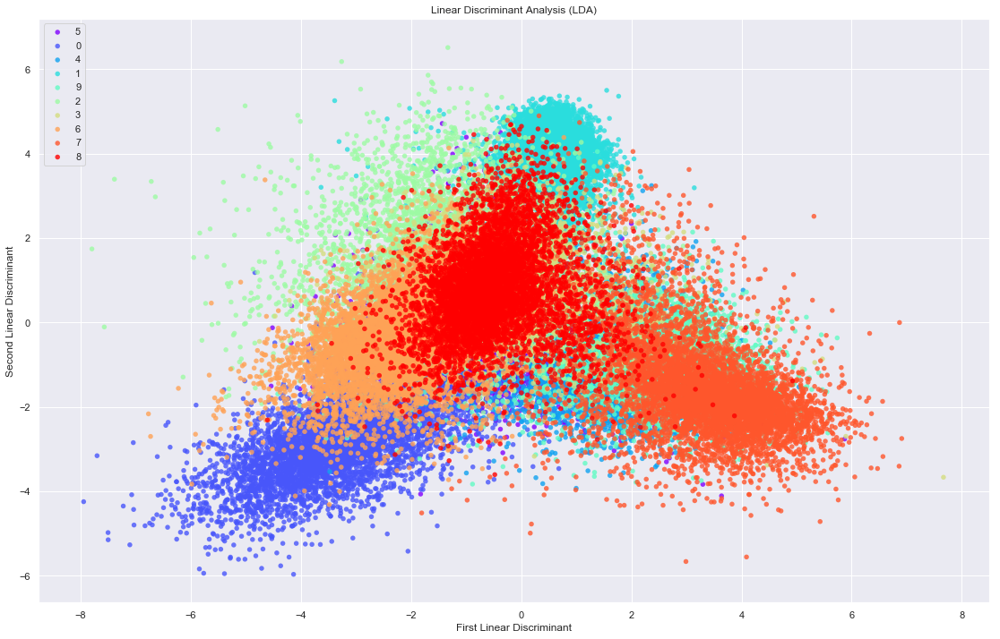

In [36]:
import matplotlib.cm as cm
groups  = lda_df.target.unique().tolist()
colors = cm.rainbow(np.linspace(0, 1, 10))
xs=list()
ys=list()
for group in groups:
    xs.append(lda_df.loc[lda_df.target== group]['LD1'].tolist())
    ys.append(lda_df.loc[lda_df.target== group]['LD2'].tolist())
    
fig = plt.figure(figsize= (19, 12))
ax = fig.add_subplot(1, 1, 1)

for x,y, color, group in zip(xs, ys, colors, groups):
    ax.scatter(x, y, alpha=0.8, c=color, edgecolors='none', s=30, label=group)

plt.title('Linear Discriminant Analysis (LDA)')
plt.xlabel('First Linear Discriminant')
plt.ylabel("Second Linear Discriminant")
plt.legend(loc=2)
plt.show();

*From the scatter plot above, we can see that the data points are more clearly clustered when using LDA with as compared to implementing PCA with class labels. This is an inherent advantage in having class labels to supervise the method with.*

*Time for the interactive plot*

In [37]:
# Plot LDA graph
# I have just ploted first 2000 data points beacuse rendering 60000 data points in Jupyter notebook will slow it down
data = [
    go.Scatter(
    x = X_lda[:2000,0],
    y = X_lda[:2000,1],
    mode = 'markers',
    showlegend = True,
    marker = dict(
        size = 8,
        color = y_train[:2000],
        colorscale ='Rainbow',
        showscale = False,
        opacity = 0.8,
        line = dict(
            width = 2,
            color = 'rgb(255, 255, 255)'
        )
    )
)]

layout = go.Layout(
    title= 'Linear Discriminant Analysis (LDA)',
    hovermode= 'closest',
    xaxis= dict(
         title= 'First Linear Discriminant',
        ticklen= 8,
        zeroline= False,
        gridwidth= 2,
    ),
    yaxis=dict(
        title= 'Second Linear Discriminant',
        ticklen= 8,
        gridwidth= 2,
    ),
    showlegend= False
)

fig = dict(data=data, layout=layout)
pyo.iplot(fig, filename='LDA_plot')

*Now the time has come to discuss a Dimensionality reduction technique, which is considered to be the best for visualising High Dimensional Data*

<h3> t - Distributed Stochastic Neighbor Embedding (t-SNE)</h3>

***t-Distributed Stochastic Neighbor Embedding (t-SNE)*** *is an unsupervised, non-linear technique primarily used for data exploration and visualizing high-dimensional data. In simpler terms, t-SNE gives you a feel or intuition of how the data is arranged in a high-dimensional space. It was developed by Laurens van der Maatens and Geoffrey Hinton in 2008.*

**Why t-SNE  over PCA ?**

*PCA is a linear dimension reduction technique that seeks to maximize variance and preserves large pairwise distances. In other words, things that are different end up far apart. This can lead to poor visualization especially when dealing with non-linear manifold structures. Think of a manifold structure as any geometric shape like: cylinder, ball, curve, etc.*

*t-SNE differs from PCA by preserving only small pairwise distances or local similarities whereas PCA is concerned with preserving large pairwise distances to maximize variance.*

**How t-SNE works ?**

*The t-SNE algorithm calculates a similarity measure between pairs of instances in the high dimensional space and in the low dimensional space. It then tries to optimize these two similarity measures using a cost function. Let’s break that down into 3 basic steps.*

- Step 1 is  to measure similarities between points in the high dimensional space. Think of a bunch of data points scattered on a 2D space (Figure 2). For each data point (x<sub>i</sub>) we’ll center a Gaussian distribution over that point. Then we measure the density of all points (x<sub>j</sub>) under that Gaussian distribution. Then renormalize for all points. This gives us a set of probabilities (P<sub>ij</sub>) for all points. Those probabilities are proportional to the similarities. All that means is, if data points x<sub>1</sub> and x<sub>2</sub> have equal values under this gaussian circle then their proportions and similarities are equal and hence you have local similarities in the structure of this high-dimensional space. The Gaussian distribution or circle can be manipulated using what’s called perplexity, which influences the variance of the distribution (circle size) and essentially the number of nearest neighbors. Normal range for perplexity is between 5 and 50.


<center><img src="https://miro.medium.com/max/700/1*1dWlX9m9ZOcZ77uhpl21RA.png"></center>


- Step 2 is similar to step 1, but instead of using a Gaussian distribution you use a Student t-distribution with one degree of freedom, which is also known as the Cauchy distribution . This gives us a second set of probabilities (Q<sub>ij</sub>) in the low dimensional space. As you can see the Student t-distribution has heavier tails than the normal distribution. The heavy tails allow for better modeling of far apart distances.


<center><img src="https://miro.medium.com/max/700/1*bLzoEHeWHZIMas9vJb7ctA.png"></center>


- The last step is that we want these set of probabilities from the low-dimensional space (Q<sub>ij</sub>) to reflect those of the high dimensional space (P<sub>ij</sub>) as best as possible. We want the two map structures to be similar. We measure the difference between the probability distributions of the two-dimensional spaces using Kullback-Liebler divergence (KL). I won’t get too much into KL except that it is an asymmetrical approach that efficiently compares large P<sub>ij</sub> and Q<sub>ij</sub> values. Finally, we use gradient descent to minimize our KL cost function. 

*Enough of discussion lets jump on to the implementation now.*

In [120]:
from sklearn.manifold import TSNE
# Invoking the t-SNE method
tsne = TSNE()
X_tsne = tsne.fit_transform(X_train_scaled[:10000])

In [122]:
tsne_df= pd.DataFrame({'C1': X_tsne[:,0], 'C2': X_tsne[:,1], 'target': y_train[:10000]})

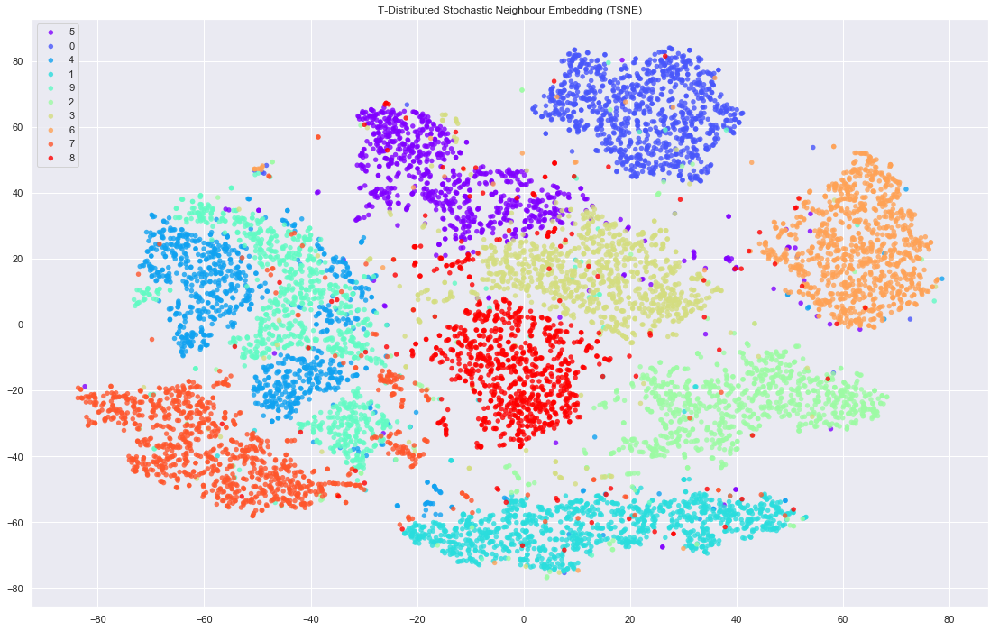

In [123]:
import matplotlib.cm as cm
groups  = tsne_df.target.unique().tolist()
colors = cm.rainbow(np.linspace(0, 1, 10))
xs=list()
ys=list()
for group in groups:
    xs.append(tsne_df.loc[tsne_df.target== group]['C1'].tolist())
    ys.append(tsne_df.loc[tsne_df.target== group]['C2'].tolist())
    
fig = plt.figure(figsize= (19, 12))
ax = fig.add_subplot(1, 1, 1)

for x,y, color, group in zip(xs, ys, colors, groups):
    ax.scatter(x, y, alpha=0.8, c=color, edgecolors='none', s=30, label=group)

plt.title('T-Distributed Stochastic Neighbour Embedding (TSNE)')
plt.legend(loc=2)
plt.show();

*You can clearly see all the clusters are represented very clearly that too even with 10000 points, thats why I told that TSNE is the best. Try running it with all 60000 data points and you will get a better Viz.*

In [124]:
# performs t-sne with different perplexity values and their repective plots..
from sklearn.manifold import TSNE
def perform_tsne(X_data, y_data, perplexities, n_iter=1000, img_name_prefix='t-sne'):
        
    for index,perplexity in enumerate(perplexities):
        # perform t-sne
        print('\n performing tsne with perplexity {} and with {} iterations at max'.format(perplexity, n_iter))
        X_reduced = TSNE(perplexity=perplexity).fit_transform(X_data)
        print('Done..')
        
        # prepare the data for seaborn         
        print('Creating plot for this t-sne visualization..')
        df = pd.DataFrame({'x':X_reduced[:,0], 'y':X_reduced[:,1] ,'label':y_data})
        
        # draw the plot in appropriate place in the grid
        sns.lmplot(data=df, x='x', y='y', hue='label', fit_reg=False, size=8,\
                   palette="Set1",markers=['^','v','s','o', '1','2'])
        plt.title("perplexity : {} and max_iter : {}".format(perplexity, n_iter))
        plt.show()
        print('Done')

Now TSNE algorithm has some hyperparameters which can tuned to get more better results, I have created a function above which is going take in your predictors, target variable and some values of perplexities like  
**perform_tsne(X_data = X_train_scaled, y_data=y_train, perplexities =[5, 10, 15, 20, 25, 40, 50])**
and going to plot the graph for each perplexities values. 

*The perplexity is related to the number of nearest neighbors that is used in other manifold learning algorithms. Larger datasets usually require a larger perplexity. Consider selecting a value between 5 and 50. Default value of perplexity is 30 and the plot for that we have already created. Try this out for different perplexities value and let us know which one gave you the better results.*

*There are 60000 data points to train and if you feed in around 5 to 6 values of perplexity, It's gonna take time. Make sure you run it overnight or it's a weekend Go watch a movie and if don't want to go out Just Netflix and Chill 😋.*

**What to expect next:**

- Modeling using sklearn K-Nearest Neighbors, Random Forest, Linear SVC Classifier and comparing them based on accuracy.
- Multilayer Perceptron model Using Keras
- Simple Convolutional Neural Network Using Keras
- Larger Convolutional Neural Network using Keras
- Finalising the model based on Accuracy


**Next is some good stuff**

*Improving Model's Performance using Image Augmentation*
- Feature Standardization using Keras
- ZCA Whitening

**Conclusion**